# Reconstructing a measured spectral image from a bucket detector

This review actively reconstructs **all8192 real detector spectra and2048 wavelengths** of the author-provided tomato-slice acquisition. The native64×64 field is preserved.

The selected method is the published direct Walsh least-squares inverse. It is a numerical benchmark against an independently rerun original method; neither result is independently measured specimen truth. The paper also studies trained DC-Net outputs at128×128: that different learned method is outside this selected task and is not represented by cached or invented fresh results. Here the scientific comparisons concern native spectral structure, original-method agreement, retrospective sampling and noise-sensitive limitations.


In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,spectral_bins
from src.solvers import reconstruct
from src import visualization as vis
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'svg.fonttype':'none','pdf.fonttype':42})
data=load_observations()
print('Real observation:',data['measurements'].shape,data['measurements'].dtype)
print('Measured wavelength endpoints [nm]:',data['wavelength_nm'][[0,-1]])


Real observation: (8192, 2048) float64
Measured wavelength endpoints [nm]: [514.7382 750.2672]


## Physics and direct inverse

Let $F$ be the spatial image with one column per spectral channel, $H=W\otimes W$ the unnormalized2D Walsh matrix, and $M$ the positive-minus-negative detector spectra after undoing the acquisition permutation. Stable detector offsets cancel within each pair. The model is $\mathbb{E}[M]=HF$, where $W$ has64 sequency-ordered rows of signs and $H^TH=4096I$. The direct inverse is $\widehat F=H^TM/4096$.

The local implementation evaluates this identical operator with explicit binary butterflies and the Gray-code/bit-reversal ordering. It does not import the upstream reconstruction library. Small negative values are retained, and no wavelength-dependent fitted normalization is introduced. Independent tests check original stage outputs, constant and impulse images, orthogonality and the adjoint identity.


In [2]:
start=time.perf_counter()
submission=reconstruct(data)
fresh=submission['reconstruction'][0]
inverse_seconds=time.perf_counter()-start
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',**submission)
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
assert exit_code==0,report
print('Fresh full inverse seconds:',inverse_seconds)
print(json.dumps(report,indent=2))
with np.load(ROOT/'notebooks/reference_outputs/upstream_views.npz',allow_pickle=False) as f:
    upstream={k:f[k] for k in f.files}
np.testing.assert_array_equal(upstream['edges_nm'],vis.EDGES_NM)
yx=upstream['pixel_yx']
np.testing.assert_array_equal(fresh[yx[:,0],yx[:,1]],upstream['pixel_spectra'])
print('All three identified original native pixel spectra agree exactly.')


Fresh full inverse seconds: 0.5374433000106364
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0,
    "nrmse": 0.0,
    "relative_measurement_residual": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-11
    },
    "relative_measurement_residual": {
      "comparison": "<=",
      "boundary": 1e-11
    }
  },
  "errors": []
}
All three identified original native pixel spectra agree exactly.


## Spectral structure and original-method agreement

The eight images sum measured wavelengths within25nm bands between530 and730nm, on one shared display scale. The full2048-channel reconstruction above is evaluated, not only these display bands. Counts retain the LED spectrum, sensor response and sample transmission. A band-brightness difference therefore does not by itself identify a chemical concentration.

The following comparison separates the result of this task's independent original run from the newly computed local result. Exact zero differences are labelled explicitly; the displayed symmetric residual range is a visualization convention, not a fabricated nonzero error.


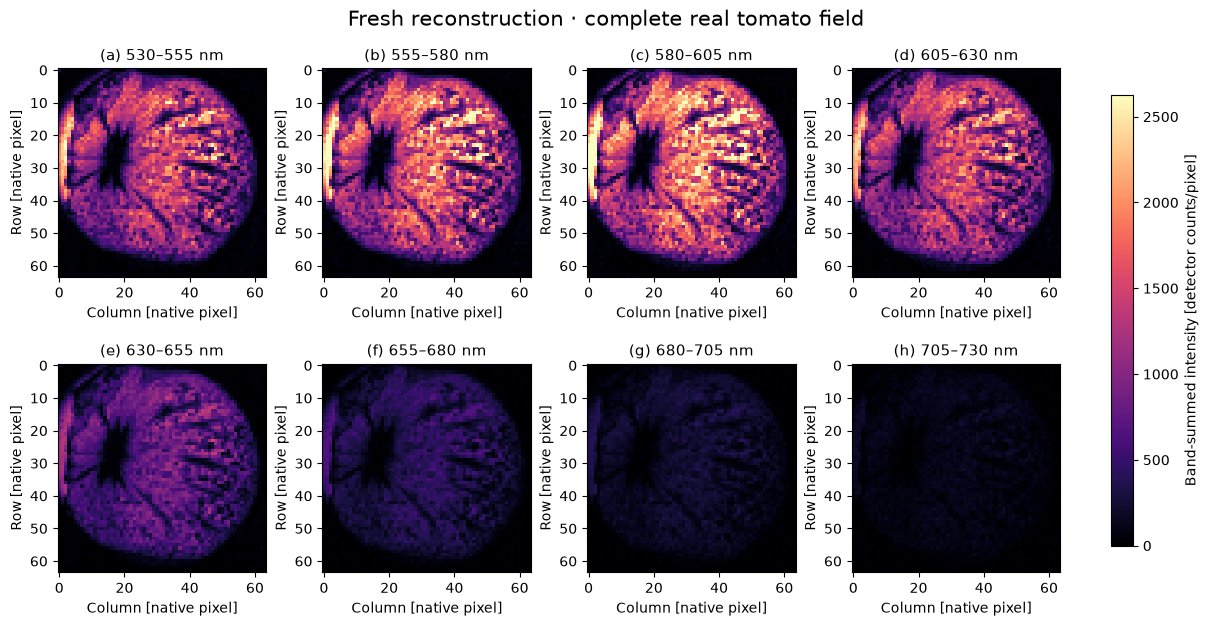

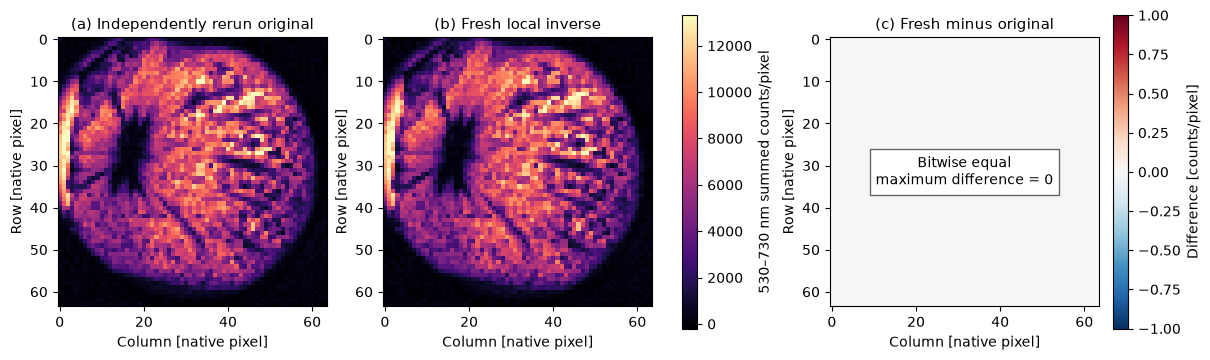

Band-image max absolute difference [summed counts/pixel]: 0.0


In [3]:
experiments=vis.compute_experiments(data,fresh)
figure1=vis.spectral_plate(experiments);plt.show()
figure2=vis.parity_plate(experiments['band_sum'],upstream['band_sum']);plt.show()
print('Band-image max absolute difference [summed counts/pixel]:',float(np.max(abs(experiments['band_sum']-upstream['band_sum']))))


## Acquisition information, ordering and noise-sensitive limits

These are **retrospective subsets of actual detector pairs**, with every displayed inverse computed anew. Four orders retain the recorded acquisition prefix, the lowest Walsh indices, seeded random actual pairs, or those same random pairs with the measured DC pair explicitly retained. The fourth group controls the missing-DC brightness failure in unrestricted random sampling; ordering effects should not be attributed solely to the measurement count. Missing coefficients are placed at zero by the same published minimum-norm inverse. NRMSE uses the full measured inverse as a method reference; it is not error to independent truth. The100% case coincides exactly with that reference.

Complement sums should be nearly independent of the displayed pattern for a perfectly stable source and detector. Their measured variation exposes acquisition drift without inventing a drift correction. Native pixel spectra and negative-pixel fractions reveal where the signed noisy inverse becomes hard to interpret. No known noise variance or independent absolute transmission calibration is claimed.


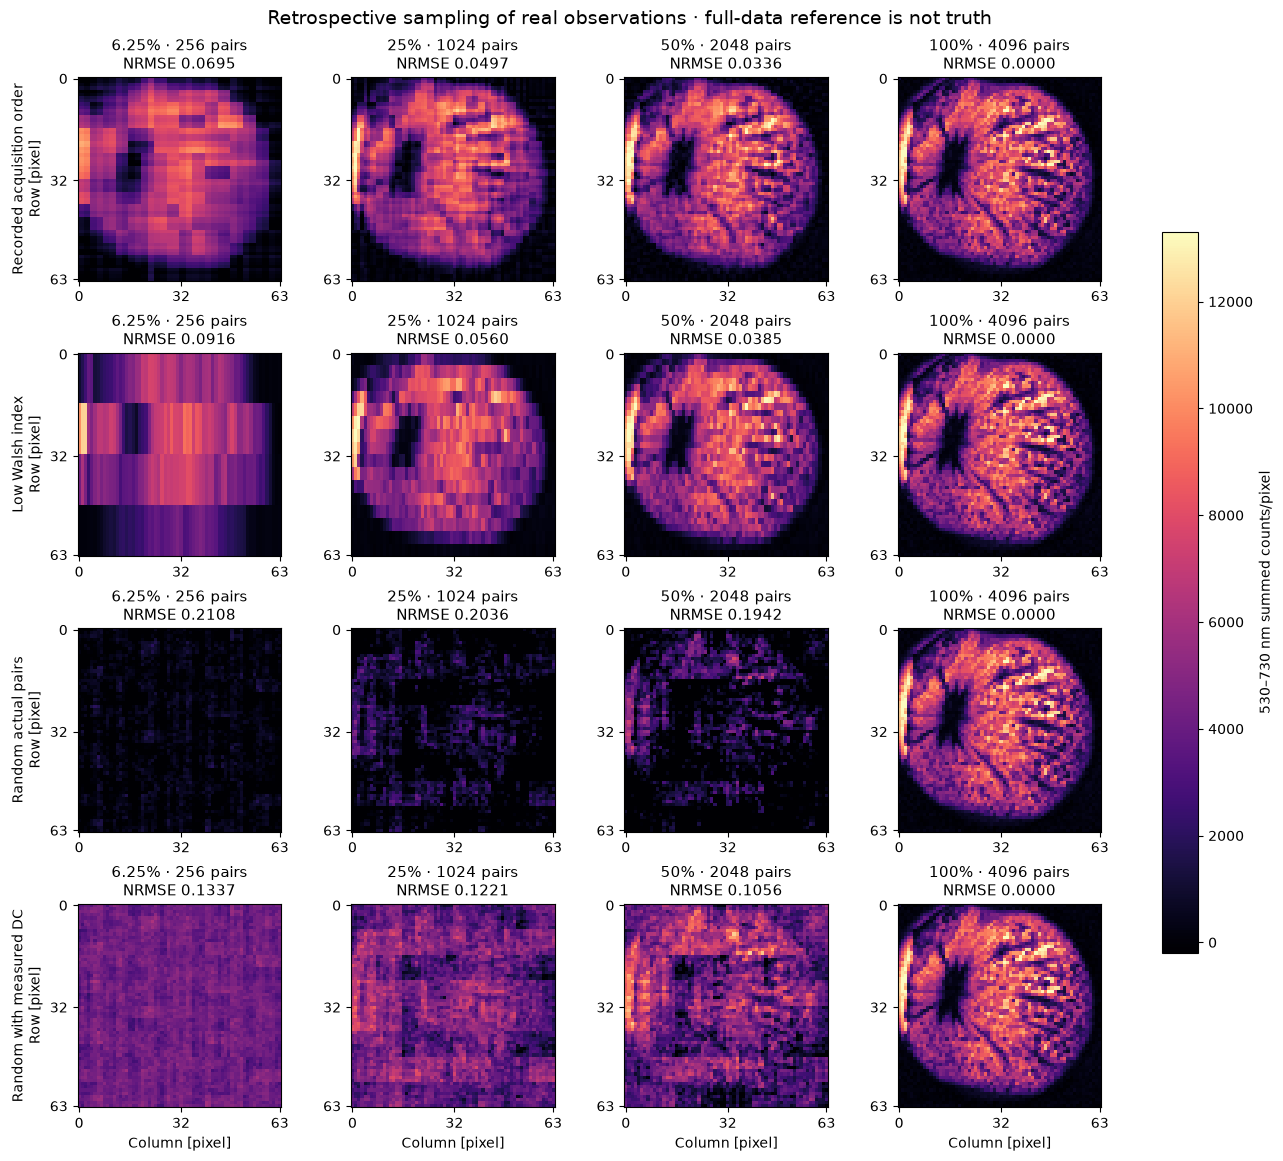

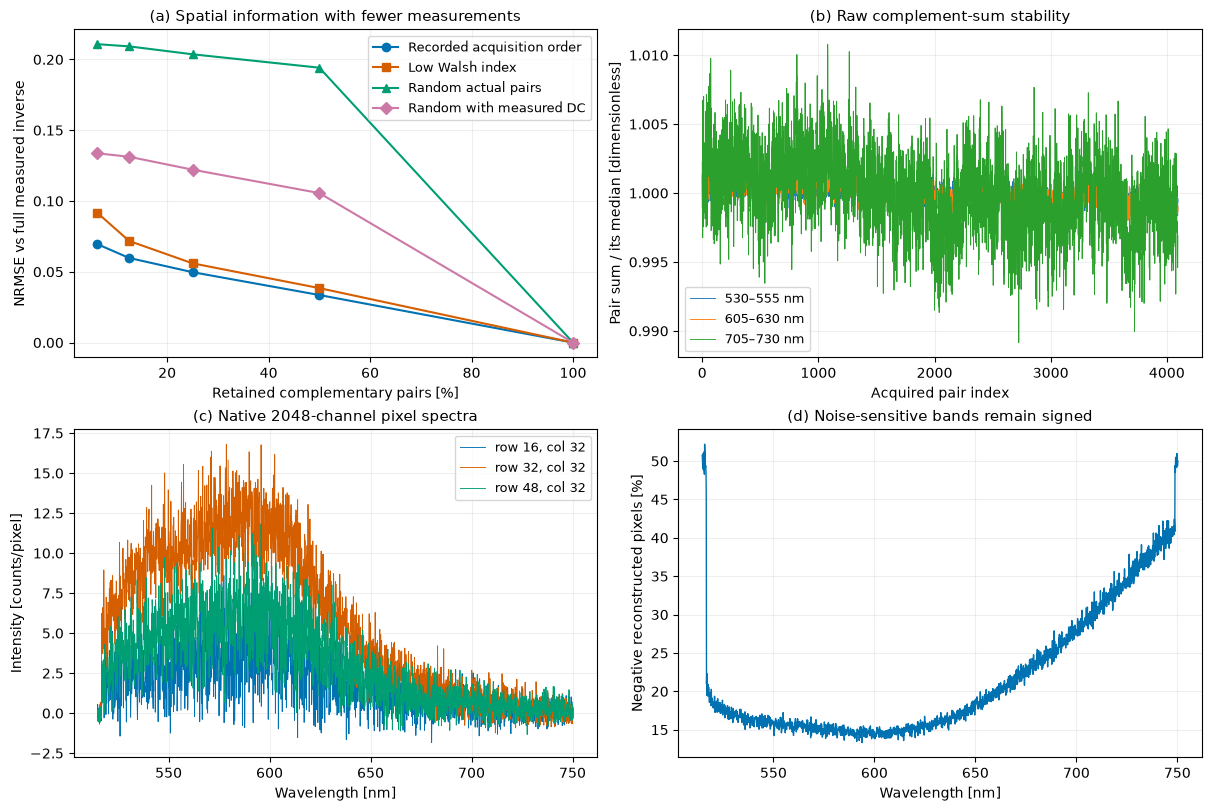

Method-reference NRMSE (rows: acquisition, low Walsh, random, random+DC):
[[0.06951468 0.05977756 0.04973172 0.03359094 0.        ]
 [0.09162106 0.07179303 0.05598109 0.0384704  0.        ]
 [0.21077089 0.2092338  0.2036417  0.1941686  0.        ]
 [0.13369505 0.13125769 0.12214869 0.10560041 0.        ]]
Nominal pair-count exposure durations [s]: [ 0.7168  1.4336  2.8672  5.7344 11.4688]
Actual source complete acquisition duration [s]: 11.4674765625
Signed negative-pixel fraction: 0.22338199615478516


In [4]:
figure3=vis.sampling_plate(experiments);plt.show()
figure4=vis.diagnostics_plate(data,fresh,experiments);plt.show()
print('Method-reference NRMSE (rows: acquisition, low Walsh, random, random+DC):')
print(experiments['nrmse'])
print('Nominal pair-count exposure durations [s]:',experiments['counts']*2*1400e-6)
print('Actual source complete acquisition duration [s]:',11.4674765625)
print('Signed negative-pixel fraction:',float(np.mean(fresh<0)))


## Result and conclusion

The complete native real spectral cube is reconstructed and judged freshly. Original stage and full-output equality plus independent physical identities establish numerical method reproduction. They do not establish absolute specimen accuracy. Sampling experiments show the tradeoff between acquired spatial coefficients and method-reference agreement; spectral and complement-sum diagnostics expose measurement limitations.

The acquisition is reused, not synthetically regenerated. Source version, data hashes, exact measured timing, environment, independent original runs, numerical tolerances, test results and figure review are recorded in `test/validation.md`.
